In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from datetime import datetime

In [10]:
df = pd.read_csv('E-Commerce Sales Analytics.csv')

In [11]:
df.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [12]:
df.describe()

,order_id,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,1443.520003,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,10001.000000,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   str    
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   str    
 4   region            5000 non-null   str    
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   str    
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), str(4)
memory usage: 468.9 KB


In [19]:
print(df['revenue'].mean()) # rata-rata
print(df['revenue'].median()) # median
print(df['revenue'].std()) # standar deviasi
print(df['revenue'].quantile(0.25)) # Q1
print(df['revenue'].quantile(0.75)) # Q3

1021.955148
796.65
825.5842191911942
354.5275
1515.69


C:\Users\user\AppData\Local\Temp\ipykernel_7464\2055328351.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')


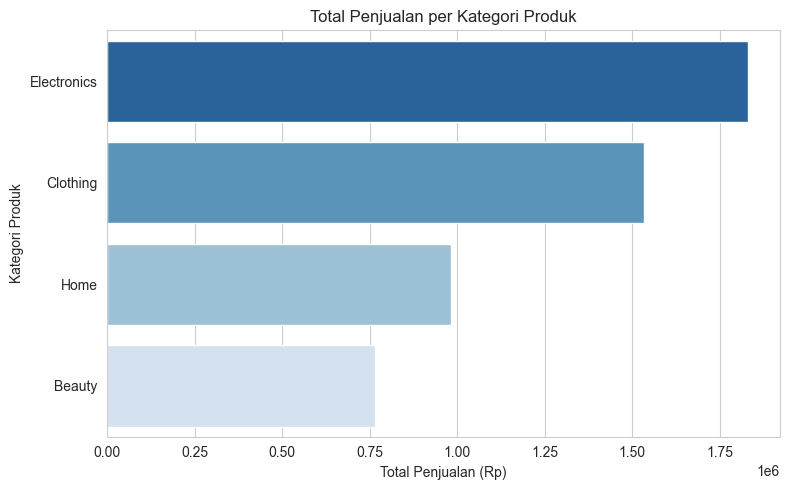

In [22]:
total_kategori = df.groupby('product_category')['revenue'].sum().sort_values(ascending=False)
plt.figure(figsize=(8,5))
sns.barplot(x=total_kategori.values, y=total_kategori.index, palette='Blues_r')
plt.title('Total Penjualan per Kategori Produk')
plt.xlabel('Total Penjualan (Rp)')
plt.ylabel('Kategori Produk')
plt.tight_layout()
plt.show()

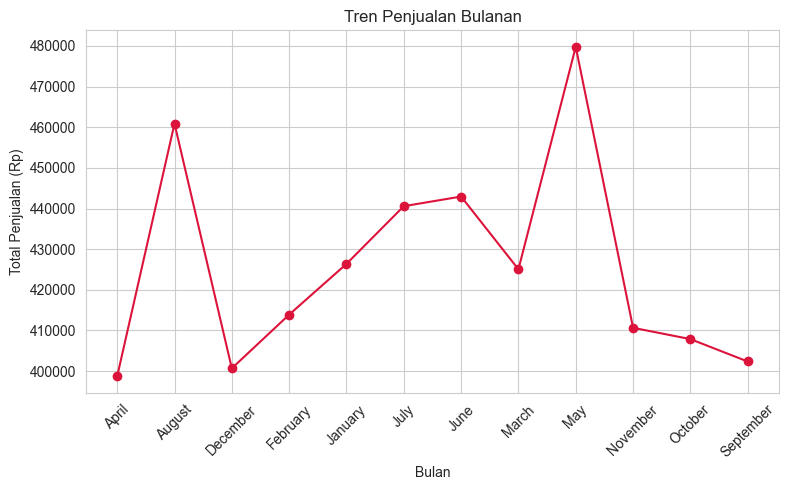

In [29]:
# Mengubah kolom menjadi format datetime
df['order_date'] = pd.to_datetime(df['order_date'])

# Mengambil nama bulan
df['bulan'] = df['order_date'].dt.strftime('%B')

# Menghitung total revenue setiap bulan
tren_bulanan = df.groupby('bulan')['revenue'].sum()

# Membuat grafik
plt.figure(figsize=(8, 5))
plt.plot(
    tren_bulanan.index,
    tren_bulanan.values,
    marker='o',
    color='crimson'
)

plt.title('Tren Penjualan Bulanan')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


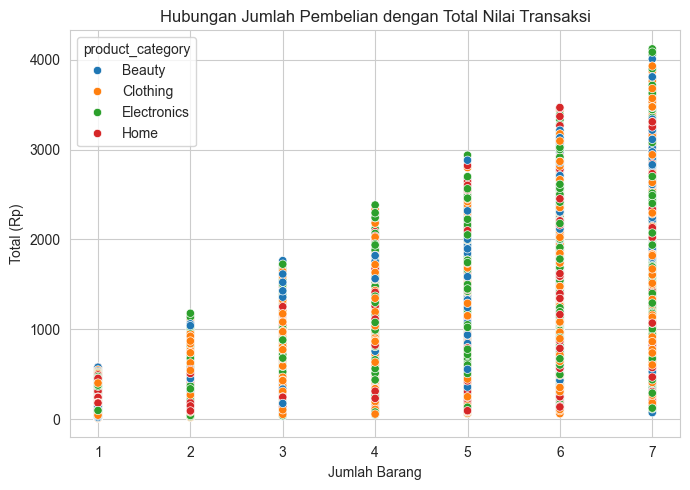

In [30]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='quantity', y='revenue', hue='product_category')
plt.title('Hubungan Jumlah Pembelian dengan Total Nilai Transaksi')
plt.xlabel('Jumlah Barang')
plt.ylabel('Total (Rp)')
plt.tight_layout()
plt.show()

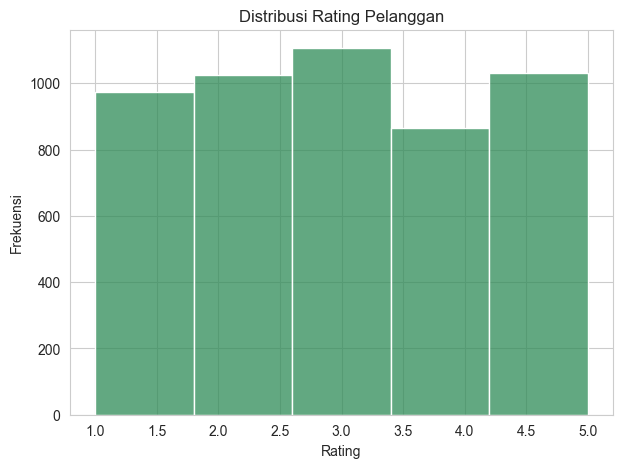

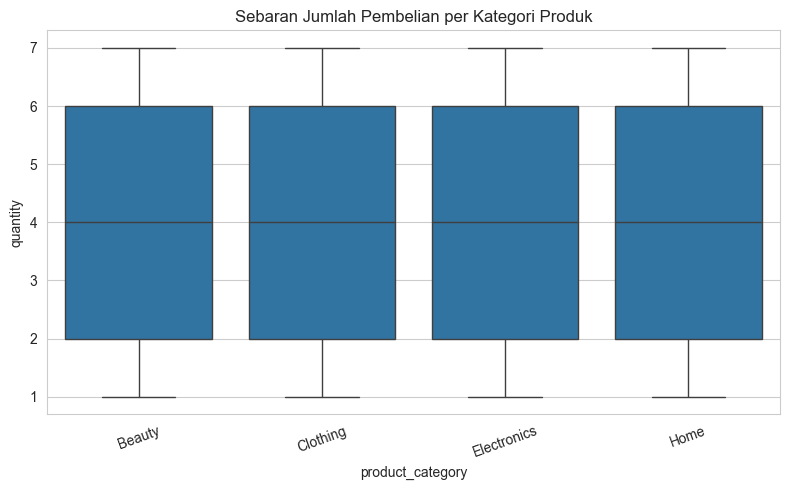

In [ ]:
# Histogram distribusi rating pelanggan
plt.figure(figsize=(7,5))
sns.histplot(df['customer_rating'], bins=5, color='seagreen')
plt.title('Distribusi Rating Pelanggan')
plt.xlabel('Rating')
plt.ylabel('Frekuensi')
plt.show()
# Boxplot jumlah pembelian per kategori (deteksi outlier)
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='product_category', y='quantity')
plt.title('Sebaran Jumlah Pembelian per Kategori Produk')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [34]:

# === LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART ===

# 1. RINGKASAN STATISTIK
total_penjualan = df['revenue'].sum()
rata_rata_transaksi = df['revenue'].mean()

kategori_terlaris = (
    df.groupby('product_category')['quantity']
    .sum()
    .idxmax()
)

wilayah_teratas = (
    df.groupby('region')['revenue']
    .sum()
    .idxmax()
)

rating_rata_rata = df['customer_rating'].mean()

print("=== LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART ===")

print("\n1. Ringkasan Statistik")
print(f"Total Penjualan       : Rp {total_penjualan:,.0f}")
print(f"Rata-rata Transaksi   : Rp {rata_rata_transaksi:,.0f}")
print(f"Kategori Terlaris     : {kategori_terlaris}")
print(f"Wilayah Teratas       : {wilayah_teratas}")
print(f"Rating Rata-rata      : {rating_rata_rata:.2f} / 5")


# 2. TEMUAN UTAMA (INSIGHT)
print("\n2. Temuan Utama (Insight)")

# Kategori dengan revenue tertinggi
revenue_kategori = df.groupby('product_category')['revenue'].sum()
kategori_revenue_tertinggi = revenue_kategori.idxmax()

# Metode pembayaran paling sering digunakan
metode_pembayaran = df['payment_method'].mode()[0]

# Rata-rata waktu pengiriman
rata_pengiriman = df['delivery_days'].mean()

print(
    f"- Kategori {kategori_revenue_tertinggi} "
    f"menghasilkan revenue tertinggi sebesar "
    f"Rp {revenue_kategori.max():,.0f}."
)
print(f"- Metode pembayaran paling umum adalah {metode_pembayaran}.")
print(f"- Rata-rata waktu pengiriman adalah {rata_pengiriman:.1f} hari.")

# Wilayah dengan revenue terendah
revenue_wilayah = df.groupby('region')['revenue'].sum()
wilayah_terendah = revenue_wilayah.idxmin()

print(
    f"- Wilayah dengan revenue terendah adalah {wilayah_terendah}, "
    f"sebesar Rp {revenue_wilayah.min():,.0f}."
)


# 3. POTENSI OUTLIER
print("\n3. Potensi Outlier")

kolom_outlier = ['revenue', 'quantity', 'unit_price', 'delivery_days']

for kolom in kolom_outlier:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah_outlier = (
        (df[kolom] < batas_bawah) |
        (df[kolom] > batas_atas)
    ).sum()

    print(f"- {kolom}: {jumlah_outlier} data berpotensi outlier.")


# 4. REKOMENDASI BISNIS
print("\n4. Rekomendasi Bisnis")

# Kategori dengan jumlah penjualan terendah
jumlah_kategori = df.groupby('product_category')['quantity'].sum()
kategori_terendah = jumlah_kategori.idxmin()

# Wilayah dengan revenue tertinggi
wilayah_revenue_tertinggi = revenue_wilayah.idxmax()

print(
    f"- Pertahankan stok dan promosi kategori {kategori_terlaris} "
    "karena memiliki jumlah penjualan tertinggi."
)
print(
    f"- Evaluasi strategi pemasaran kategori {kategori_terendah} "
    "untuk meningkatkan jumlah penjualannya."
)
print(
    f"- Pelajari strategi penjualan di wilayah {wilayah_revenue_tertinggi} "
    "untuk diterapkan di wilayah lain."
)
print(
    "- Evaluasi data transaksi yang berpotensi outlier "
    "sebelum mengambil keputusan bisnis."
)
print(
    "- Pantau rating pelanggan dan waktu pengiriman "
    "untuk meningkatkan kualitas pelayanan."
)


=== LAPORAN ANALISIS DATA PENJUALAN NUSANTARA MART ===

1. Ringkasan Statistik
Total Penjualan       : Rp 5,109,776
Rata-rata Transaksi   : Rp 1,022
Kategori Terlaris     : Electronics
Wilayah Teratas       : West
Rating Rata-rata      : 2.97 / 5

2. Temuan Utama (Insight)
- Kategori Electronics menghasilkan revenue tertinggi sebesar Rp 1,829,899.
- Metode pembayaran paling umum adalah Card.
- Rata-rata waktu pengiriman adalah 6.1 hari.
- Wilayah dengan revenue terendah adalah East, sebesar Rp 1,236,044.

3. Potensi Outlier
- revenue: 67 data berpotensi outlier.
- quantity: 0 data berpotensi outlier.
- unit_price: 0 data berpotensi outlier.
- delivery_days: 0 data berpotensi outlier.

4. Rekomendasi Bisnis
- Pertahankan stok dan promosi kategori Electronics karena memiliki jumlah penjualan tertinggi.
- Evaluasi strategi pemasaran kategori Beauty untuk meningkatkan jumlah penjualannya.
- Pelajari strategi penjualan di wilayah West untuk diterapkan di wilayah lain.
- Evaluasi data transa